# 02 · Manifold — principal-curve trajectory (non-branching)

The malignant manifold is a single continuous body, not a Y — so it is fit with scFates **`curve`** (non-branching), not a tree. The curve is checked for **folds** (a re-embedded linear strip can fold into a U and defeat neighbour-based continuity metrics), rooted **data-driven at the Gast/pSom-high, cycling-low developmental origin** (Gast/pSom are early, Crest is late), and pseudotime is verified to run origin→Crest and **not** to track proliferation. Deliverable: `manifold.h5ad`, `manifold.pdf`.

*Reproducibility:* Harmony's KMeans is not seed-deterministic, so the principal-node/tip **index** the root lands on can shift by a few between runs; the biological root (Gast/pSom-high origin) is invariant.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f} (elongated -> linear)')

malignant manifold: 5645 cells
UMAP principal-axis ratio (major/minor singular value): 1.65 (elongated -> linear)


### Fit principal curve + fold-freeness check
Fit `curve` at a few node counts and measure the self-approach ratio (min graph-distant node separation / median edge length): >1 means no fold. All fits give 0 forks (non-branching) and a fold-free curve; N=20 is used.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.96
curve N=30: 2 tips, 0 forks | self-approach 2.80
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.96 (>1 = fold-free)


### Root at the Gast/pSom-high developmental origin
For each curve tip, read the mean smoothed Gast/pSom/Crest of nearby cells; root at the tip maximising Gast+pSom−Crest (developmental origin), never at the Crest terminus or a cycling state.

In [ ]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
rho_c,_ = spearmanr(t, cyc)
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (cell-cycle is not the trajectory axis)')

tip 0: Gast=+0.0100 pSom=+0.0113 Crest=+0.0102
tip 2: Gast=+0.0162 pSom=+0.0037 Crest=+0.0061
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.475 p=0.0e+00
  pSom_sm: rho=+0.107 p=1.0e-15
  Crest_sm: rho=+0.320 p=3.0e-134
Neural-crest-high decile mean pseudotime = 0.58
Somitogenesis-high decile mean pseudotime = 0.84
Gastrulation-high decile mean pseudotime = 0.07
caveat: pseudotime vs cycling score rho = +0.29 (cell-cycle is not the trajectory axis)


### Render the fitted curve on the manifold (fold visible if present)

single fold-free curve from Gast/pSom-high root to Crest-high terminus


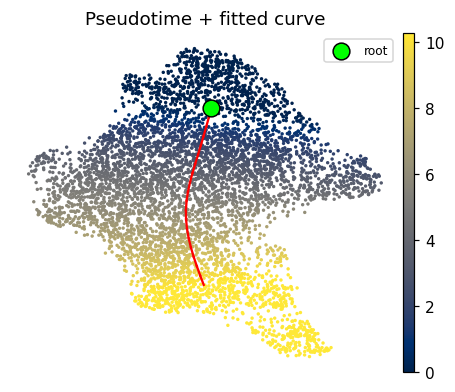

In [ ]:
F = adata.uns['graph']['F'].T; Bm = np.asarray(adata.uns['graph']['B'])>0
fig, ax = plt.subplots(figsize=(5,4))
sc.pl.umap(adata, color='t', cmap='cividis', size=20, ax=ax, show=False, frameon=False,
           title='Pseudotime + fitted curve', colorbar_loc='right')
for i in range(F.shape[0]):
    for j in range(i+1, F.shape[0]):
        if Bm[i,j]: ax.plot([F[i,0],F[j,0]],[F[i,1],F[j,1]],'r-',lw=1.5, zorder=5)
ax.scatter(F[root,0], F[root,1], c='lime', s=120, zorder=6, edgecolor='k', label='root')
ax.legend(loc='best', fontsize=8); plt.show()
print('single fold-free curve from Gast/pSom-high root to Crest-high terminus')

### Save manifold + embedding figure (deliverable)
House `(3.5,1.5)` linear strip on `X_umap_lin`, pseudotime colour — matches all downstream panels.

saved manifold.h5ad + manifold.pdf


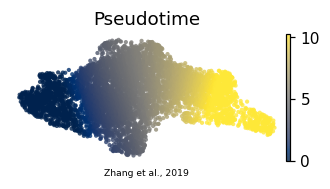

In [ ]:
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}  # drop non-serializable Edges lists
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')